# Task 1: Working with data in Python

In this unit we will focus on how to deal with data in Python. The first part involves elementary data management operations (e.g., import, conversion, output). In the second we will focus on plotting data. 

In [146]:
import pandas as pd

## Part 1: Data mingling

### 1.1 Construct complete data sets for Chicago and Potsdam for 2015

#### 1.1.1 Chicago

#### Import the data of Chicago based on local time from .csv (01/01/2015-12/31/2015)

In [147]:
# Read the CSV file
CH_15_df = pd.read_csv("data/PV_generation_Chicago_10kW_0loss_2015.csv", 
                       usecols=[1,2,5],  # what is happening here?
                       skiprows=3,  # what is happening here?
                       parse_dates=['local_time'],  # what is happening here?
                       encoding='latin1',
                       date_format='%m/%d/%Y %H:%M')
 # what is happening here?

# what is happening here?
print(CH_15_df.head(10))

           local_time  electricity  temperature
0 2014-12-31 18:00:00          0.0       -6.695
1 2014-12-31 19:00:00          0.0       -6.693
2 2014-12-31 20:00:00          0.0       -6.740
3 2014-12-31 21:00:00          0.0       -6.846
4 2014-12-31 22:00:00          0.0       -7.106
5 2014-12-31 23:00:00          0.0       -7.328
6 2015-01-01 00:00:00          0.0       -7.488
7 2015-01-01 01:00:00          0.0       -7.637
8 2015-01-01 02:00:00          0.0       -7.813
9 2015-01-01 03:00:00          0.0       -7.984


All there?

In [148]:
CH_15_df.shape 
# correct output: 8760 rows and 3 columns

(8760, 3)

In [149]:
CH_15_df.tail() # print last 5 rows

,local_time,electricity,temperature
8755,2015-12-31 13:00:00,5.892,-2.205
8756,2015-12-31 14:00:00,2.700,-2.321
8757,2015-12-31 15:00:00,0.678,-2.661
8758,2015-12-31 16:00:00,0.000,-3.462
8759,2015-12-31 17:00:00,0.000,-4.485


>Inspect the imported data. What do you notice? What is yet to be done to compile a complete data set of 2015?

#### Modify data set to include all data points for 2015

In [152]:
# Import data of 2016 into Dataframe CH_16_df
CH_16_df = pd.read_csv("data/PV_generation_Chicago_10kW_0loss_2016.csv",
                       usecols=[1,2,5],  # what is happening here? use only columns 2 3 and 6 becuase they are only the important ones to look at
                       skiprows=3,  # skip first three descriptive rows
                       parse_dates=['local_time'],  #
                       encoding='latin1',
                       date_format='%m/%d/%Y %H:%M')
 # latin enocding for tet


In [153]:
# What is happening here? We cut Out
CH_df = pd.concat([CH_15_df.iloc[6:], CH_16_df.iloc[:6]], ignore_index=True)

# 'reset_index': index aligns with the new concatenated dataframe

# Display the last 10 rows
CH_df.head(10), CH_df.tail(10)

(           local_time  electricity  temperature
 0 2015-01-01 00:00:00        0.000       -7.488
 1 2015-01-01 01:00:00        0.000       -7.637
 2 2015-01-01 02:00:00        0.000       -7.813
 3 2015-01-01 03:00:00        0.000       -7.984
 4 2015-01-01 04:00:00        0.000       -8.147
 5 2015-01-01 05:00:00        0.000       -8.221
 6 2015-01-01 06:00:00        0.000       -8.256
 7 2015-01-01 07:00:00        0.524       -8.197
 8 2015-01-01 08:00:00        3.870       -7.428
 9 2015-01-01 09:00:00        6.419       -6.125,
               local_time  electricity  temperature
 8750 2015-12-31 14:00:00        2.700       -2.321
 8751 2015-12-31 15:00:00        0.678       -2.661
 8752 2015-12-31 16:00:00        0.000       -3.462
 8753 2015-12-31 17:00:00        0.000       -4.485
 8754 2015-12-31 18:00:00        0.000       -5.308
 8755 2015-12-31 19:00:00        0.000       -5.897
 8756 2015-12-31 20:00:00        0.000       -6.220
 8757 2015-12-31 21:00:00        0.000      

#### 1.1.2 Potsdam 

#### Import the data of Potsdam based on local time from .csv (01/01/2015-12/31/2015)

>Take a look at the .csv file. What do you notice?
>Date and time are not in the same format as in chicago one and difference between utc and local is causing problems

In [154]:
# Read the CSV file
P_15_df = pd.read_csv( "data/PV_generation_Potsdam_10kW_0loss_2015_GermanFormat.csv",
    usecols=[1, 2, 5],  # Select columns 2, 3, 6 (0-indexed in Python)
    skiprows=3,  # Skip the first 3 rows (header starts at the 4th row in Python)
    delimiter=';',  # what is happening here?
    decimal=',',  # what is happening here?
    parse_dates=['local_time'], # Determine where to find the time data
    date_format='%d.%m.%Y %H:%M')

# Display the first 5 rows of the DataFrame
P_15_df.head(5)

,local_time,electricity,temperature
0,2015-01-01 01:00:00,0.0,1.574
1,2015-01-01 02:00:00,0.0,1.470
2,2015-01-01 03:00:00,0.0,1.294
3,2015-01-01 04:00:00,0.0,1.139
4,2015-01-01 05:00:00,0.0,0.949


All there?

In [155]:
P_15_df.shape
# correct output: 8760 rows and 3 columns
P_15_df.head(10)

,local_time,electricity,temperature
0,2015-01-01 01:00:00,0.000,1.574
1,2015-01-01 02:00:00,0.000,1.470
2,2015-01-01 03:00:00,0.000,1.294
3,2015-01-01 04:00:00,0.000,1.139
4,2015-01-01 05:00:00,0.000,0.949
5,2015-01-01 06:00:00,0.000,0.577
6,2015-01-01 07:00:00,0.000,0.361
7,2015-01-01 08:00:00,0.006,0.313
8,2015-01-01 09:00:00,0.323,0.611
9,2015-01-01 10:00:00,0.897,0.838


In [156]:
P_15_df.tail()

,local_time,electricity,temperature
8755,2015-12-31 20:00:00,0.0,0.225
8756,2015-12-31 21:00:00,0.0,0.223
8757,2015-12-31 22:00:00,0.0,0.271
8758,2015-12-31 23:00:00,0.0,0.197
8759,2016-01-01 00:00:00,0.0,0.024


#### Modify data set to include all data points for 2015

In [157]:
#Import data of 2014 into Dataframe CH_14_df
P_14_df = pd.read_csv( "data/PV_generation_Potsdam_10kW_0loss_2014_GermanFormat.csv",
    usecols=[1, 2, 5],  # Select columns 2, 3, 6 (0-indexed in Python)
    skiprows=3,  # Skip the first 3 rows (header starts at the 4th row in Python)
    delimiter=';',  # what is happening here?
    decimal=',',  # what is happening here?
    parse_dates=['local_time'], # Determine where to find the time data
    date_format='%d.%m.%Y %H:%M')

print(P_14_df.head(10))

           local_time  electricity  temperature
0 2014-01-01 01:00:00        0.000       -1.978
1 2014-01-01 02:00:00        0.000       -1.944
2 2014-01-01 03:00:00        0.000       -1.945
3 2014-01-01 04:00:00        0.000       -1.882
4 2014-01-01 05:00:00        0.000       -1.895
5 2014-01-01 06:00:00        0.000       -1.920
6 2014-01-01 07:00:00        0.000       -1.927
7 2014-01-01 08:00:00        0.036       -1.836
8 2014-01-01 09:00:00        0.665       -0.945
9 2014-01-01 10:00:00        1.505        0.122


In [158]:
# Create DataFrame P_df that holds all data points for 2015
P_df = pd.concat([P_14_df.iloc[-1:],P_15_df.iloc[:-1]], ignore_index=True) #merge last item from P_14 with P_15 and cut last item of 15

# Display the last 10 rows
P_df.head(5), P_df.tail(5)

(           local_time  electricity  temperature
 0 2015-01-01 00:00:00          0.0        1.667
 1 2015-01-01 01:00:00          0.0        1.574
 2 2015-01-01 02:00:00          0.0        1.470
 3 2015-01-01 03:00:00          0.0        1.294
 4 2015-01-01 04:00:00          0.0        1.139,
               local_time  electricity  temperature
 8755 2015-12-31 19:00:00          0.0        0.332
 8756 2015-12-31 20:00:00          0.0        0.225
 8757 2015-12-31 21:00:00          0.0        0.223
 8758 2015-12-31 22:00:00          0.0        0.271
 8759 2015-12-31 23:00:00          0.0        0.197)

In [159]:
P_df.head()

,local_time,electricity,temperature
0,2015-01-01 00:00:00,0.0,1.667
1,2015-01-01 01:00:00,0.0,1.574
2,2015-01-01 02:00:00,0.0,1.470
3,2015-01-01 03:00:00,0.0,1.294
4,2015-01-01 04:00:00,0.0,1.139


Are `CH_df` and `P_df` the same size?

In [160]:
CH_df.shape, P_15_df.shape

((8760, 3), (8760, 3))

### 1.2 Merge both datasets and export to .csv file

In [161]:
# what is happening here?
df = pd.merge(CH_df, P_df, on='local_time', how='inner')


# Display the first 5 rows
df.head()

,local_time,electricity_x,temperature_x,electricity_y,temperature_y
0,2015-01-01 00:00:00,0.0,-7.488,0.0,1.667
1,2015-01-01 01:00:00,0.0,-7.637,0.0,1.574
2,2015-01-01 02:00:00,0.0,-7.813,0.0,1.470
3,2015-01-01 03:00:00,0.0,-7.984,0.0,1.294
4,2015-01-01 04:00:00,0.0,-8.147,0.0,1.139


In [162]:
df.columns = ['time', 'CH_PV', 'CH_temp', 'P_PV', 'P_temp']  # what is happening here? Rename Rows

df.head()  # display the first 5 rows

,time,CH_PV,CH_temp,P_PV,P_temp
0,2015-01-01 00:00:00,0.0,-7.488,0.0,1.667
1,2015-01-01 01:00:00,0.0,-7.637,0.0,1.574
2,2015-01-01 02:00:00,0.0,-7.813,0.0,1.470
3,2015-01-01 03:00:00,0.0,-7.984,0.0,1.294
4,2015-01-01 04:00:00,0.0,-8.147,0.0,1.139


In [163]:
df.shape

(8760, 5)

Create or overwrite a .csv file at `data/pv_temp_both.csv` with `to_csv`


In [164]:
df.to_csv("data/pv_temp_both.csv", index=False) # 'index=False' excludes the row index from being written to the CSV file.

>#### What's the issue when concatenating both DataFrames? Dateformats / Different formats within the datasets. Also Timezones

### 1.3. Calculate monthly mean values

Add column with month indicator

In [169]:
df['month'] = df['time'].dt.month # only possible, when "df['time']" is a DateTime Obj.

# what is happening here?
'''
creating a new column named month which just takes month number
'''

'\ncreating a new column named month which just takes month number\n'

In [167]:
df.head()

,time,CH_PV,CH_temp,P_PV,P_temp,month
0,2015-01-01 00:00:00,0.0,-7.488,0.0,1.667,1
1,2015-01-01 01:00:00,0.0,-7.637,0.0,1.574,1
2,2015-01-01 02:00:00,0.0,-7.813,0.0,1.470,1
3,2015-01-01 03:00:00,0.0,-7.984,0.0,1.294,1
4,2015-01-01 04:00:00,0.0,-8.147,0.0,1.139,1


In [170]:
df.columns[1] # get name of column 2 (0-indexed)

'CH_PV'

First, let's create a new DataFrame `df_mean` where you can find the mean for `CH_PV` for each month.

In [178]:
# Define new DataFrame that holds monthly mean values for CH_PV_mean

df_mean = df.groupby('month')[['CH_PV']].mean().reset_index()

df_mean # Display df_mean

,month,CH_PV
0,1,1.346243
1,2,1.730405
2,3,2.253500
3,4,2.228213
4,5,2.100133
5,6,2.181668
6,7,2.319815
7,8,2.287159
8,9,2.025211
9,10,1.759021


Rename the column to `CH_PV_mean`

In [179]:
# Rename the column
df_mean.rename(columns={"CH_PV": "CH_PV_mean"}, inplace=True) # inplace=True modifies the DataFrame df_mean directly, without the need to assign the result back to a new variable.

# Display the DataFrame
df_mean

,month,CH_PV_mean
0,1,1.346243
1,2,1.730405
2,3,2.253500
3,4,2.228213
4,5,2.100133
5,6,2.181668
6,7,2.319815
7,8,2.287159
8,9,2.025211
9,10,1.759021


Now, let's overwrite and rename the DataFrame `df_mean` so you can find the mean values for `'CH_PV', 'CH_temp', 'P_PV', 'P_temp'` for each month. (same procedure)

In [180]:
# Define new DataFrame based on aggregation by month
df_mean = df.groupby('month')[['CH_PV', 'CH_temp', 'P_PV', 'P_temp']].mean().reset_index()

# what is happening here?
df_mean.rename(columns={
    "CH_PV": "CH_PV_mean", 
    "CH_temp": "CH_temp_mean",
    "P_PV": "P_PV_mean",
    "P_temp": "P_temp_mean"}, inplace=True)

# Display the DataFrame
df_mean

,month,CH_PV_mean,CH_temp_mean,P_PV_mean,P_temp_mean
0,1,1.346243,-4.393263,0.364073,1.424409
1,2,1.730405,-8.568528,1.211469,0.173976
2,3,2.253500,0.791311,1.395296,4.593698
3,4,2.228213,7.931176,1.996989,7.845300
4,5,2.100133,14.289149,2.256767,12.186503
5,6,2.181668,18.081364,2.213754,15.788471
6,7,2.319815,21.656097,2.320565,19.337390
7,8,2.287159,21.950774,2.095269,20.978305
8,9,2.025211,20.196414,1.775532,13.511504
9,10,1.759021,12.668169,1.106458,7.472549


We can transform the DataFrame back to a matrix (= 2D NumPy Array) with `.to_numpy()`

In [181]:
matrix_df_mean = df_mean.to_numpy() # convert a DataFrame to a numpy array

matrix_df_mean

array([[ 1.        ,  1.34624328, -4.39326344,  0.36407258,  1.4244086 ],
       [ 2.        ,  1.73040476, -8.56852827,  1.21146875,  0.17397619],
       [ 3.        ,  2.2535    ,  0.79131132,  1.3952965 ,  4.59369811],
       [ 4.        ,  2.2282125 ,  7.93117639,  1.99698889,  7.8453    ],
       [ 5.        ,  2.10013306, 14.28914919,  2.25676747, 12.18650269],
       [ 6.        ,  2.18166806, 18.08136389,  2.21375417, 15.78847083],
       [ 7.        ,  2.31981452, 21.65609677,  2.32056452, 19.33738978],
       [ 8.        ,  2.2871586 , 21.95077419,  2.09526882, 20.97830511],
       [ 9.        ,  2.02521111, 20.19641389,  1.77553194, 13.51150417],
       [10.        ,  1.75902148, 12.66816913,  1.10645772,  7.47254899],
       [11.        ,  1.54618863,  7.66835229,  0.56311928,  6.35873232],
       [12.        ,  0.94143952,  3.76062097,  0.4136828 ,  5.19702688]])

### 1.4 Save to .csv file

In [182]:
df_mean.to_csv("data/pv_temp_monthly_mean.csv", index=False)

# 'index=False' prevents pandas from writing row indices into the CSV file

Break ☕😎

## Part 2: Visualization

In [183]:
#In case you haven't done so, let's import our libraries

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### 2.1 Visualize monthly mean values

In [184]:
df_mean = pd.read_csv("data/pv_temp_monthly_mean.csv") # Import data from .csv into DataFrame (if no longer available from Task 1)

In [185]:
df_mean # print result

,month,CH_PV_mean,CH_temp_mean,P_PV_mean,P_temp_mean
0,1,1.346243,-4.393263,0.364073,1.424409
1,2,1.730405,-8.568528,1.211469,0.173976
2,3,2.253500,0.791311,1.395296,4.593698
3,4,2.228213,7.931176,1.996989,7.845300
4,5,2.100133,14.289149,2.256767,12.186503
5,6,2.181668,18.081364,2.213754,15.788471
6,7,2.319815,21.656097,2.320565,19.337390
7,8,2.287159,21.950774,2.095269,20.978305
8,9,2.025211,20.196414,1.775532,13.511504
9,10,1.759021,12.668169,1.106458,7.472549


#### Let's create a combined chart of the PV generation and temperature of each month

In [186]:
x = np.array(range(1,13)) # Create x values (months)
x # display

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12])

In [187]:
# Extract PV and temperature values
PV_mean = df_mean[['CH_PV_mean', 'P_PV_mean']].to_numpy() # what is happening here?
T_mean = df_mean[['CH_temp_mean', 'P_temp_mean']].to_numpy() # what is happening here?

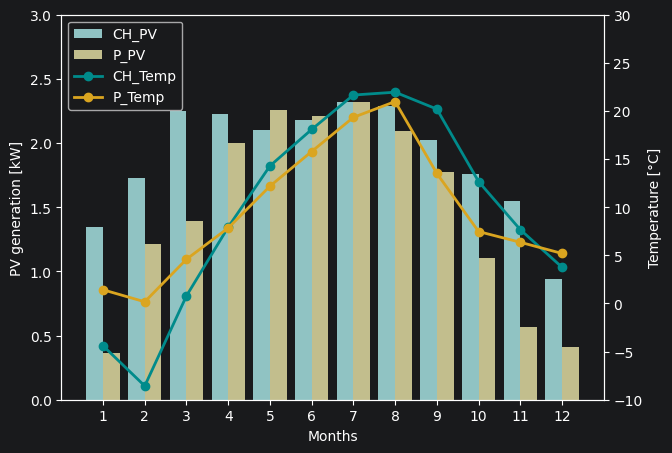

In [188]:
# Import the necessary library
import matplotlib.pyplot as plt

# what is happening here?
fig, ax1 = plt.subplots(figsize=(7,5)) 

# First Axis: Bar Chart for PV Generation
# what is happening here?
ax1.bar(x - 0.2, PV_mean[:, 0], 0.4, label='CH_PV', color='paleturquoise', alpha=0.8)
ax1.bar(x + 0.2, PV_mean[:, 1], 0.4, label='P_PV', color='palegoldenrod', alpha=0.8)

# Labelling x-axis as 'Months' and y-axis as 'PV generation [kW]'
ax1.set_xlabel('Months')
ax1.set_ylabel('PV generation [kW]')

# Setting the limits for the x-axis and y-axis manually
ax1.set_xlim(0, 13)
ax1.set_ylim(0, 3)

# Setting the x-axis ticks to match the month numbers.
ax1.set_xticks(x)

# Second Axis: Line Graph for Temperature
# what is happening here?
ax2 = ax1.twinx()

# what is happening here?
ax2.plot(x, T_mean[:, 0], color='darkcyan', linewidth=2, marker='o', label='CH_Temp')
ax2.plot(x, T_mean[:, 1], color='goldenrod', linewidth=2, marker='o', label='P_Temp')

# Labelling and setting the limits for the second y-axis
ax2.set_ylabel('Temperature [°C]')
ax2.set_ylim(-10, 30)

# what is happening here?
lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc='upper left')

# Display the entire Plot
plt.show()

In [189]:
fig.savefig("figures/PV_temp_monthly_means.pdf")
# or as PNG: fig.savefig("figures/PV_temp_monthly_means.png")

### 2.2 Visualize confidence intervals

Load the initial merged DataFrame and add a column for the hour

In [193]:
# Read the CSV file into a DataFrame
df = pd.read_csv("data/pv_temp_both.csv", parse_dates=['time'])

# Add a new column 'hour' with information on the hour of the day
df['hour'] = df['time'].dt.hour

# Display the first 5 rows of the DataFrame
df.head()

,time,CH_PV,CH_temp,P_PV,P_temp,hour
0,2015-01-01 00:00:00,0.0,-7.488,0.0,1.667,0
1,2015-01-01 01:00:00,0.0,-7.637,0.0,1.574,1
2,2015-01-01 02:00:00,0.0,-7.813,0.0,1.470,2
3,2015-01-01 03:00:00,0.0,-7.984,0.0,1.294,3
4,2015-01-01 04:00:00,0.0,-8.147,0.0,1.139,4


Chicago DataFrame with median values

In [200]:
# Compute median values for Chicago PV generation and save to new DataFrame df_CH
# df_mean = df.groupby('month')[['CH_PV']].mean().reset_index()

df_CH = df.groupby('hour')['CH_PV'].agg(['median']).reset_index()

In [197]:
df_CH

,hour,median
0,0,0.000
1,1,0.000
2,2,0.000
3,3,0.000
4,4,0.000
5,5,0.000
6,6,0.000
7,7,0.870
8,8,2.670
9,9,4.447


Now the complete Chicago DataFrame with median values and confidence intervals

In [201]:
# PV quantiles
df_CH = df.groupby('hour')['CH_PV'].agg(['median', lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)]).reset_index()
df_CH.columns = ['hour', 'CH_PV_median', 'CH_PV_25_quant', 'CH_PV_75_quant']

# add temperature indicators
df_temp = df.groupby('hour')['CH_temp'].agg(['median', lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)]).reset_index()
df_temp.columns = ['hour', 'CH_Temp_median', 'CH_Temp_25_quant', 'CH_Temp_75_quant']

# join two dataframes
df_CH = pd.merge(df_CH, df_temp, on='hour')

df_CH

,hour,CH_PV_median,CH_PV_25_quant,CH_PV_75_quant,CH_Temp_median,CH_Temp_25_quant,CH_Temp_75_quant
0,0,0.000,0.000,0.000,9.1740,1.19100,16.9790
1,1,0.000,0.000,0.000,8.8735,0.86100,16.7890
2,2,0.000,0.000,0.000,8.6670,0.79975,16.5235
3,3,0.000,0.000,0.000,8.2930,0.53800,16.0150
4,4,0.000,0.000,0.000,7.9830,0.56000,15.9160
5,5,0.000,0.000,0.000,7.7680,0.48000,15.8640
6,6,0.000,0.000,0.279,7.9660,0.49400,15.9180
7,7,0.870,0.287,1.605,8.4730,0.61900,16.7010
8,8,2.670,1.482,3.764,9.6860,1.48500,17.6840
9,9,4.447,2.748,5.730,10.7800,2.57000,18.9240


Now for Potsdam: DataFrame with median values and quantiles

In [202]:
# PV quantiles
df_P = df.groupby('hour')['P_PV'].agg(['median', lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)]).reset_index()
df_P.columns = ['hour', 'P_PV_median', 'P_PV_25_quant', 'P_PV_75_quant']

# Temperature quantiles
df_temp = df.groupby('hour')['P_temp'].agg(['median', lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)]).reset_index()
df_temp.columns = ['hour', 'P_Temp_median', 'P_Temp_25_quant', 'P_Temp_75_quant']

# join two dataframes
df_P = pd.merge(df_P, df_temp, on='hour')

df_P

,hour,P_PV_median,P_PV_25_quant,P_PV_75_quant,P_Temp_median,P_Temp_25_quant,P_Temp_75_quant
0,0,0.000,0.000,0.000,7.2370,2.256,11.80400
1,1,0.000,0.000,0.000,6.8365,2.210,11.38350
2,2,0.000,0.000,0.000,6.4720,1.864,10.82325
3,3,0.000,0.000,0.000,6.0510,1.820,10.51300
4,4,0.000,0.000,0.000,5.7120,1.710,9.97100
5,5,0.000,0.000,0.000,5.6880,1.572,10.00300
6,6,0.000,0.000,0.286,6.0110,1.590,10.54400
7,7,0.319,0.000,1.243,6.8530,1.698,11.67400
8,8,1.433,0.241,2.788,7.4790,2.369,13.10700
9,9,2.962,0.974,4.625,8.9670,3.894,14.77400


In [203]:
# what is happening here?
h = df_CH['hour'].values
y_CH = df_CH.drop('hour', axis=1).values
y_P = df_P.drop('hour', axis=1).values

Create visualization

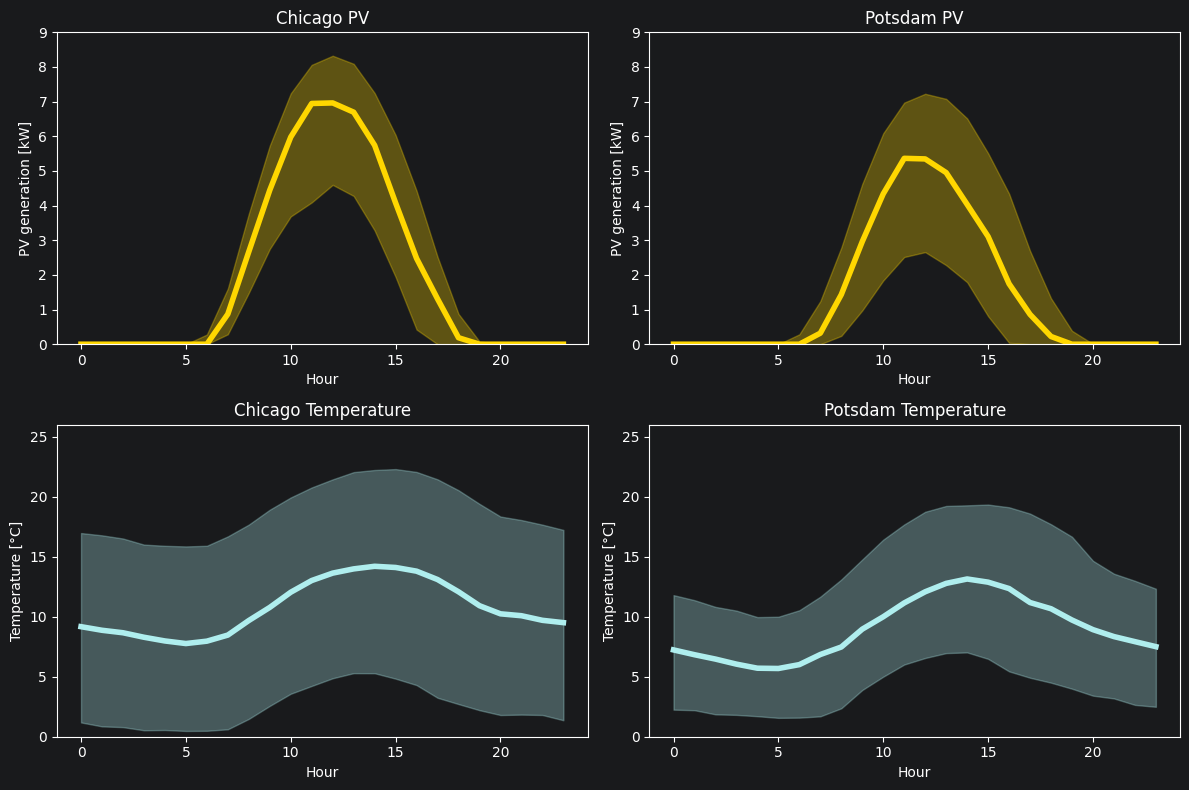

In [204]:
import matplotlib.pyplot as plt

# Set common limits of y-axis to compare the plots
PV_ymax = 9
Temp_ymax = 26

# Initialize a 2x2 subplot figure
fig, axs = plt.subplots(2, 2, figsize=(12,8)) # use 'axs' when creating a figure with multiple subplots

# Chicago PV
axs[0, 0].fill_between(h, y_CH[:,2], y_CH[:,1], color='gold', alpha=0.3)
axs[0, 0].plot(h, y_CH[:,0], color='gold', linewidth=4.0)
axs[0, 0].set_ylim(0, PV_ymax)
axs[0, 0].set_title('Chicago PV')
axs[0, 0].set_ylabel('PV generation [kW]')
axs[0, 0].set_xlabel('Hour')

# Potsdam PV
axs[0, 1].fill_between(h, y_P[:,2], y_P[:,1], color='gold', alpha=0.3)
axs[0, 1].plot(h, y_P[:,0], color='gold', linewidth=4.0)
axs[0, 1].set_ylim(0, PV_ymax)
axs[0, 1].set_title('Potsdam PV')
axs[0, 1].set_ylabel('PV generation [kW]')
axs[0, 1].set_xlabel('Hour')

# Chicago Temperature
axs[1, 0].fill_between(h, y_CH[:,5], y_CH[:,4], color='paleturquoise', alpha=0.3)
axs[1, 0].plot(h, y_CH[:,3], color='paleturquoise', linewidth=4.0)
axs[1, 0].set_ylim(0, Temp_ymax)
axs[1, 0].set_ylabel('Temperature [°C]')
axs[1, 0].set_title('Chicago Temperature')
axs[1, 0].set_xlabel('Hour')

# Potsdam Temperature
axs[1, 1].fill_between(h, y_P[:,5], y_P[:,4], color='paleturquoise', alpha=0.3)
axs[1, 1].plot(h, y_P[:,3], color='paleturquoise', linewidth=4.0)
axs[1, 1].set_ylim(0, Temp_ymax)
axs[1, 1].set_ylabel('Temperature [°C]')
axs[1, 1].set_title('Potsdam Temperature')
axs[1, 1].set_xlabel('Hour')

# Adjust layout for neat appearance
plt.tight_layout()
plt.show()


In [205]:
# save figure
fig.savefig('figures/PV_temp_daily_confidence.pdf')

done 👍